# IBM Quantum & Vishnu Institute of Technology
## Qiskit Fall Fest 2026
### Challenge 4: Quantum Correlation Switch

---

### **Problem Statement**
In challenge 3, how a quantum circuit can produce correlated outcomes was investigated. Now, design a circuit that switches between correlated and opposite measurement outcomes. Your goal is to create two different two-qubit behaviors using only a small number of quantum gates.

### **Design Constraints**
- Use exactly **2 qubits**.
- **Measure both qubits**.
- Use **no more than 4 quantum gates** before measurement.
- Use **only gates introduced during the workshop**.
- Be created and executed using **Qiskit**.
- Use **100 shots** for each experiment.

### **Your Task**
- **Part A – Correlated Outcomes**: Design a two-qubit circuit with measurement results predominantly `00` and `11`.
- **Part B – Opposite Outcomes**: Modify your circuit so measurement results are predominantly `01` and `10`.
- **Part C – Compare**: Compare the two circuits using histograms and explain the physical mechanisms.


## Step 1: Environment Setup and Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

backend = AerSimulator()
SHOTS = 100
print(f"Backend initialized. Experiment shots: {SHOTS}")


Backend initialized. Experiment shots: 100


## Part A — Correlated Outcomes (Predominantly `00` and `11`)

### **Think Before You Run (Prediction for Part A)**
- **Circuit Design**: Prepare the Bell state $|\Phi^+\rangle$ using an $H$ gate on qubit 0 and a CNOT ($CX$) gate from qubit 0 to qubit 1 (2 gates $\le 4$).
  $$|00\rangle \xrightarrow{H_0} \frac{|0\rangle + |1\rangle}{\sqrt{2}}|0\rangle \xrightarrow{CX_{0,1}} \frac{|00\rangle + |11\rangle}{\sqrt{2}} = |\Phi^+\rangle$$
- **Predicted Outcomes**:
  - Predominant outcomes: **`00`** and **`11`** (~50% each).
  - Out of 100 shots, all 100 shots will be distributed between `00` and `11`.
  - Outcomes `01` and `10` have zero probability.


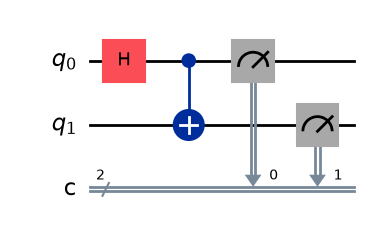

In [2]:
# Part A Circuit: Correlated Outcomes
qc_part_a = QuantumCircuit(2, 2)

# Gates: H on qubit 0, CNOT from qubit 0 to 1 (2 gates <= 4)
qc_part_a.h(0)
qc_part_a.cx(0, 1)

# Measure both qubits
qc_part_a.measure([0, 1], [0, 1])

# Draw the circuit
qc_part_a.draw('mpl')


Part A (Correlated) Measurement Results: {'00': 47, '11': 53}


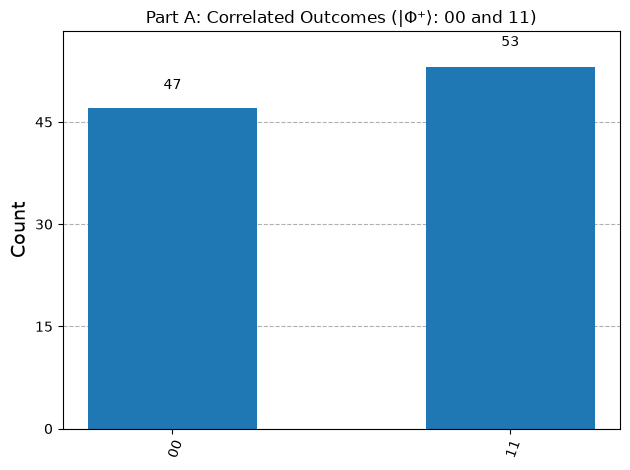

In [3]:
# Execute Part A for 100 shots
result_part_a = backend.run(qc_part_a, shots=SHOTS).result()
counts_part_a = result_part_a.get_counts()

print("Part A (Correlated) Measurement Results:", counts_part_a)

# Plot histogram
plot_histogram(counts_part_a, title="Part A: Correlated Outcomes (|Φ⁺⟩: 00 and 11)")


## Part B — Opposite Outcomes (Predominantly `01` and `10`)

### **Think Before You Run (Prediction for Part B)**
- **Circuit Design (The Switch Mechanism)**:
  To switch the correlation from identical (`00`, `11`) to opposite (`01`, `10`), we apply a Pauli-$X$ gate to qubit 1:
  $$|\Phi^+\rangle \xrightarrow{X_1} \frac{|01\rangle + |10\rangle}{\sqrt{2}} = |\Psi^+\rangle$$
  Total gates: $H(0) + CX(0,1) + X(1) = 3$ gates before measurement (satisfies $\le 4$ gate constraint).
- **Predicted Outcomes**:
  - Predominant outcomes: **`01`** and **`10`** (~50% each).
  - The measurement outcomes are now anti-correlated: when qubit 0 is 0, qubit 1 is 1; when qubit 0 is 1, qubit 1 is 0.
  - Outcomes `00` and `11` have zero probability.


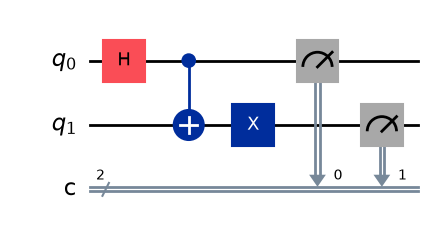

In [4]:
# Part B Circuit: Opposite Outcomes
qc_part_b = QuantumCircuit(2, 2)

# Switch configuration: H on 0, CX(0,1), followed by X on 1 (3 gates <= 4)
qc_part_b.h(0)
qc_part_b.cx(0, 1)
qc_part_b.x(1)

# Measure both qubits
qc_part_b.measure([0, 1], [0, 1])

# Draw the circuit
qc_part_b.draw('mpl')


Part B (Opposite) Measurement Results: {'01': 53, '10': 47}


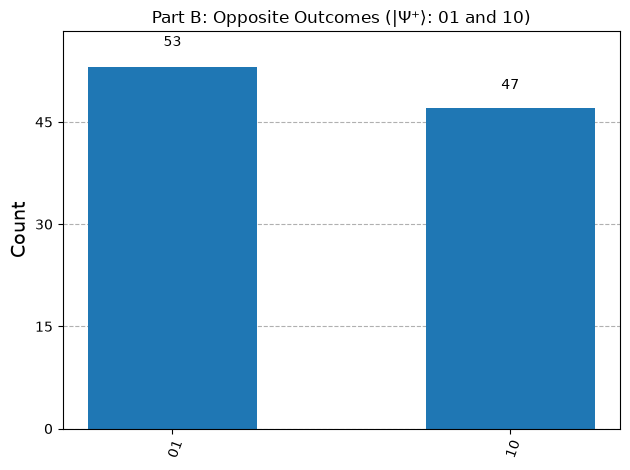

In [5]:
# Execute Part B for 100 shots
result_part_b = backend.run(qc_part_b, shots=SHOTS).result()
counts_part_b = result_part_b.get_counts()

print("Part B (Opposite) Measurement Results:", counts_part_b)

# Plot histogram
plot_histogram(counts_part_b, title="Part B: Opposite Outcomes (|Ψ⁺⟩: 01 and 10)")


## Part C — Comparison and Analysis

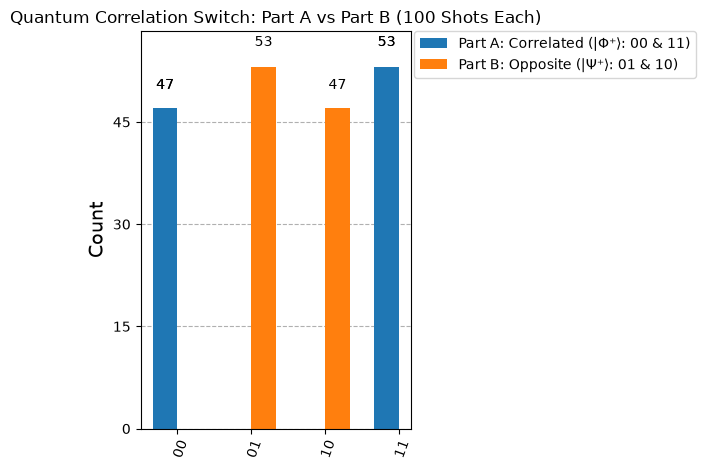

In [6]:
# Compare Part A and Part B using a single histogram
plot_histogram(
    [counts_part_a, counts_part_b],
    legend=['Part A: Correlated (|Φ⁺⟩: 00 & 11)', 'Part B: Opposite (|Ψ⁺⟩: 01 & 10)'],
    title='Quantum Correlation Switch: Part A vs Part B (100 Shots Each)'
)


## Comprehensive Explanations

### **1. Which outcomes are dominant in Part A?**
- In Part A, outcomes **`00`** and **`11`** dominate exclusively (~50% each). 
- Outcomes `01` and `10` never appear ($0\%$ probability).

### **2. Which outcomes are dominant in Part B?**
- In Part B, outcomes **`01`** and **`10`** dominate exclusively (~50% each).
- Outcomes `00` and `11` never appear ($0\%$ probability).

### **3. What changed between the two circuits?**
- We added a single **Pauli-$X$ gate** acting on qubit 1 (the target qubit) after the entangling CNOT gate.
- This serves as an exact **quantum correlation switch**, converting the circuit from a symmetric Bell state ($|\Phi^+\rangle$) to an anti-symmetric Bell state ($|\Psi^+\rangle$) using 3 total gates ($\le 4$ gates constraint).

### **4. Why did the measurement relationship change?**
- Quantum entanglement links the state of qubit 0 directly to qubit 1:
  - In Part A, the state is $|\Phi^+\rangle = \frac{1}{\sqrt{2}}(|0\rangle_0 |0\rangle_1 + |1\rangle_0 |1\rangle_1)$. Measuring either qubit gives a 50% chance of 0 or 1, but the other qubit is guaranteed to match it identically.
  - In Part B, the $X$ gate acts as a bit-flip operator: $X|0\rangle = |1\rangle$ and $X|1\rangle = |0\rangle$. Applying $X$ to qubit 1 maps:
    $$|00\rangle \mapsto |01\rangle \quad \text{and} \quad |11\rangle \mapsto |10\rangle$$
    This yields the Bell state $|\Psi^+\rangle = \frac{1}{\sqrt{2}}(|0\rangle_0 |1\rangle_1 + |1\rangle_0 |0\rangle_1)$.
  - Consequently, the relationship flips from **perfect positive correlation** to **perfect anti-correlation (opposite outcomes)**.

### **5. Think Before You Run Analysis:**
- **Will all four possible outcomes appear?**  
  No! In an ideal simulator without noise, only 2 of the 4 computational basis states have non-zero probability amplitudes in each experiment ($00, 11$ in Part A; $01, 10$ in Part B).
- **Why might some outcomes be much more frequent than others?**  
  Because quantum superposition with entanglement concentrates the entire probability amplitude ($|\alpha|^2 + |\beta|^2 = 0.5 + 0.5 = 1.0$) exclusively into the entangled basis pairs, leaving destructive interference / zero amplitude on the remaining states.
